# Experiment 4: Advanced Text Pre-processing
**Mini-project:** Resume Analyzer Using Natural Language Processing (Group 28)

**Objective:** Implement stop-word removal with custom lists, stemming, lemmatization, noise handling, multilingual text processing and entity anonymization.

Open in Colab: [Exp4_Advanced_Preprocessing.ipynb](https://colab.research.google.com/github/GnsShubham06/resume-analyzer-nlp/blob/main/notebooks/experiments/Exp4_Advanced_Preprocessing.ipynb) &nbsp;|&nbsp; Run with **Runtime → Run all**.
Data: 100 resumes (20 per domain); the screenshots in the report use five fictional (synthetic) resumes.

In [1]:
# ---- Setup: runs in Google Colab and locally --------------------------------
# In Colab this cell downloads the project repository (code + anonymised
# dataset) from GitHub and installs the packages Colab does not ship with.
import os, sys, subprocess, warnings
warnings.filterwarnings("ignore")
REPO = "https://github.com/GnsShubham06/resume-analyzer-nlp"
if "google.colab" in sys.modules:
    if not os.path.isdir("/content/resume-analyzer-nlp"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/resume-analyzer-nlp"], check=True)
    os.chdir("/content/resume-analyzer-nlp")
    extra = ['langdetect']
    if extra:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *extra], check=True)
else:  # local run from notebooks/experiments/
    for _ in range(3):
        if os.path.isfile("requirements.txt"):
            break
        os.chdir("..")
sys.path.insert(0, os.getcwd())

import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)

import spacy
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:  # model not installed yet (fresh Colab runtime)
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm", "-q"], check=True)
    import importlib, site
    importlib.invalidate_caches(); importlib.reload(site)
    import en_core_web_sm
    nlp = en_core_web_sm.load()

%config InlineBackend.figure_format = "retina"
import pandas as pd
pd.set_option("display.max_colwidth", 120)
df = pd.read_csv("data/resume_dataset.csv")
df["extracted_text"] = df["extracted_text"].fillna("")
print("Project folder:", os.path.basename(os.getcwd()), "| resumes:", len(df))

Project folder: resume-analyzer-nlp | resumes: 100


In [2]:
# Five fictional (synthetic) resumes used for the screenshots - one per domain
SAMPLE_IDS = {"Engineering": "ENG_06", "HR": "HR_06", "Finance": "FIN_07",
              "Healthcare": "HLT_04", "Agriculture": "AGR_02"}
FOOTER = "Synthetic resume - fictional person"
def resume_text(rid):
    """Raw text of a fictional resume, without the 'synthetic resume' footer line."""
    t = df.set_index("resume_id").loc[rid, "extracted_text"]
    return "\n".join(l for l in t.split("\n") if not l.startswith(FOOTER)).strip()

import re
text = resume_text("HLT_04")          # fictional Healthcare resume (Arjun D'Souza)
noisy = text + "\nPage 1 of 2\nCurriculum Vitae\nâ€“ Excellentttt communication skills!!!!  www.example.com/arjun"

## a. Noise handling

In [3]:
MOJIBAKE = {"â€“": "–", "â€”": "—", "â€™": "'", "â€œ": '"', "â€\x9d": '"', "Ã©": "é"}
TEMPLATE = re.compile(r"^(page \d+ of \d+|curriculum vitae|resume)$", re.I)
def handle_noise(t):
    for bad, good in MOJIBAKE.items():
        t = t.replace(bad, good)
    lines = []
    for l in t.split("\n"):
        l = re.sub(r"(?:https?://|www\.)\S+", "", l)          # URLs
        l = re.sub(r"^\s*[–—•\-]\s*", "", l)                   # bullet symbols
        l = re.sub(r"([A-Za-z])\1{2,}", r"\1", l)              # Excellentttt -> Excellent
        l = re.sub(r"([!?.,])\1+", r"\1", l)                   # !!!! -> !
        l = l.strip()
        if l and not TEMPLATE.match(l):
            lines.append(l)
    return "\n".join(lines)
denoised = handle_noise(noisy)
print("BEFORE (tail):", noisy.replace("\n", " | ")[-101:])
print("AFTER  (tail):", denoised.replace("\n", " | ")[-64:])

BEFORE (tail): i | Page 1 of 2 | Curriculum Vitae | â€“ Excellentttt communication skills!!!!  www.example.com/arjun
AFTER  (tail): s | Gujarati, Bengali, Marathi | Excellent communication skills!


## b. Entity anonymization

In [4]:
CITIES = ["Mumbai", "Pune", "Delhi", "Chennai", "Kolkata", "Bengaluru", "Hyderabad", "Lucknow", "Indore",
          "Nagpur", "Nashik", "Jaipur", "Ahmedabad", "Mysuru", "Coimbatore", "Chandigarh", "Bhopal", "Kochi"]
def anonymize(t):
    counts = {}
    def sub(pattern, tag, s, flags=0):
        new, n = re.subn(pattern, tag, s, flags=flags); counts[tag] = counts.get(tag, 0) + n; return new
    lines = t.split("\n")
    lines[0], counts["[NAME]"] = "[NAME]", 1              # first line of a resume = candidate name
    t = "\n".join(lines)
    t = sub(r"[\w.+-]+@[\w-]+\.[\w.]+", "[EMAIL]", t)
    t = sub(r"\+?\d[\d\s-]{7,}\d", "[PHONE]", t)
    t = sub(r"\b(?:" + "|".join(CITIES) + r")\b", "[LOCATION]", t)
    return t, counts
anon, counts = anonymize(denoised)
print("\n".join(anon.split("\n")[:9]))
print(counts)
spacy_only = [(e.text, e.label_) for d in nlp.pipe(denoised.split("\n")) for e in d.ents
              if e.label_ in ("PERSON", "GPE")]
print("spaCy NER alone:", spacy_only)

[NAME]
Clinical Research Coordinator
[LOCATION] | [EMAIL] | [PHONE]
Summary
Clinical Research Coordinator with 3 years of experience in clinical trial coordination. Committed to safe,
compassionate, evidence-based patient care.
Experience
Clinical Research Coordinator, Kindwell Children's Hospital, [LOCATION]
Feb 2023 - Present
{'[NAME]': 1, '[EMAIL]': 1, '[PHONE]': 1, '[LOCATION]': 3}
spaCy NER alone: [("Arjun D'Souza", 'PERSON'), ('Mar 2022 - Jul 2023', 'PERSON'), ('Key Skills', 'PERSON'), ('Physiotherapy', 'GPE'), ('B.Sc.', 'GPE'), ('Radiology', 'GPE'), ('Gujarati', 'GPE')]


## c. Stop words: library lists and a resume-specific list

In [5]:
from nltk.corpus import stopwords
no_tags = re.sub(r"\[[A-Z]+\]", " ", anon)          # placeholders are not words
toks = [t.lower() for t in nltk.word_tokenize(no_tags) if t.isalpha()]
nltk_stop = set(stopwords.words("english"))
spacy_stop = nlp.Defaults.stop_words
NEGATIONS = {"no", "nor", "not"}
RESUME_WORDS = {"responsible", "responsibilities", "duties", "skills", "summary", "experience",
                "objective", "resume", "curriculum", "vitae"}
custom = (nltk_stop - NEGATIONS) | RESUME_WORDS
rows = []
for name, sw in [("NLTK", nltk_stop), ("spaCy", spacy_stop), ("NLTK + resume words", custom)]:
    kept = [t for t in toks if t not in sw]
    rows.append((name, len(sw), len(toks), len(kept), " ".join(kept[:5]) + "..."))
display(pd.DataFrame(rows, columns=["stop-word list", "list size", "tokens before", "tokens after",
                                    "first kept tokens"]))

,stop-word list,list size,tokens before,tokens after,first kept tokens
0,NLTK,198,183,151,clinical research coordinator summary clinical...
1,spaCy,326,183,150,clinical research coordinator summary clinical...
2,NLTK + resume words,205,183,145,clinical research coordinator clinical research...


## d. Stemming vs lemmatization

In [6]:
from nltk.stem import LancasterStemmer, PorterStemmer, SnowballStemmer, WordNetLemmatizer
from nltk.corpus import wordnet as wn
words = ["calibrated", "analysers", "monitoring", "studies", "organised", "vaccines", "compliance",
         "counselled", "maintained", "was"]
wnl = WordNetLemmatizer()
def wn_pos(tag):
    return {"J": wn.ADJ, "V": wn.VERB, "R": wn.ADV}.get(tag[0], wn.NOUN)
tags = dict(nltk.pos_tag(words))
tab = pd.DataFrame({
    "word": words,
    "Porter": [PorterStemmer().stem(w) for w in words],
    "Snowball": [SnowballStemmer("english").stem(w) for w in words],
    "Lancaster": [LancasterStemmer().stem(w) for w in words],
    "WordNet (no POS)": [wnl.lemmatize(w) for w in words],
    "WordNet (+POS)": [wnl.lemmatize(w, wn_pos(tags[w])) for w in words],
    "spaCy lemma": [nlp(w)[0].lemma_ for w in words]})
display(tab)

,word,Porter,Snowball,Lancaster,WordNet (no POS),WordNet (+POS),spaCy lemma
0,calibrated,calibr,calibr,calibr,calibrated,calibrate,calibrate
1,analysers,analys,analys,analys,analyser,analyser,analyser
2,monitoring,monitor,monitor,monit,monitoring,monitor,monitor
3,studies,studi,studi,study,study,study,study
4,organised,organis,organis,org,organised,organise,organise
5,vaccines,vaccin,vaccin,vaccin,vaccine,vaccine,vaccine
6,compliance,complianc,complianc,comply,compliance,compliance,compliance
7,counselled,counsel,counsel,counsel,counselled,counsel,counsel
8,maintained,maintain,maintain,maintain,maintained,maintain,maintain
9,was,wa,was,was,wa,be,be


## e. Multilingual text processing

In [7]:
import unicodedata
from langdetect import DetectorFactory, detect_langs
DetectorFactory.seed = 0
lines = ["Managed pharmacy inventory and cold-chain storage for vaccines.",
         "फार्मेसी के स्टॉक और टीकों के कोल्ड-चेन भंडारण का प्रबंधन किया।",
         "शेतकऱ्यांसाठी ठिबक सिंचन प्रशिक्षण आयोजित केले.",
         "Gestion des stocks de pharmacie et suivi des vaccins."]
def script_of(t):
    names = [unicodedata.name(c, "").split()[0] for c in t if c.isalpha()]
    return max(set(names), key=names.count)
rows = []
for l in lines:
    lang = detect_langs(l)[0]
    rows.append((l[:40], script_of(l), f"{lang.lang}:{lang.prob}", script_of(l) == "LATIN" and lang.lang == "en"))
display(pd.DataFrame(rows, columns=["line", "script", "language (prob.)", "keep for English model"]))

,line,script,language (prob.),keep for English model
0,Managed pharmacy inventory and cold-chai,LATIN,en:0.999997510160761,True
1,फार्मेसी के स्टॉक और टीकों के कोल्ड-चेन,DEVANAGARI,hi:0.9999974934808865,False
2,शेतकऱ्यांसाठी ठिबक सिंचन प्रशिक्षण आयोजि,DEVANAGARI,mr:0.9999960893840009,False
3,Gestion des stocks de pharmacie et suivi,LATIN,fr:0.9999949779797151,False


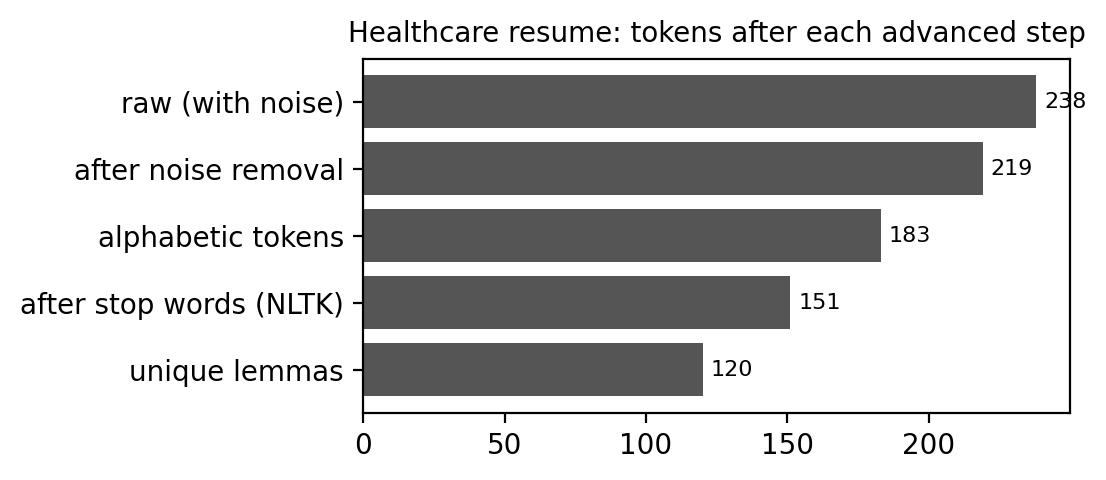

In [8]:
import matplotlib.pyplot as plt
from nltk.stem import WordNetLemmatizer
after_stop = [t for t in toks if t not in nltk_stop]
lemmas = [wnl.lemmatize(t, wn_pos(p)) for t, p in nltk.pos_tag(after_stop)]
steps = {"raw (with noise)": len(noisy.split()), "after noise removal": len(denoised.split()),
         "alphabetic tokens": len(toks), "after stop words (NLTK)": len(after_stop),
         "unique lemmas": len(set(lemmas))}
fig, ax = plt.subplots(figsize=(5.6, 2.5))
bars = ax.barh(list(steps)[::-1], list(steps.values())[::-1], color="#555555")
ax.bar_label(bars, padding=3, fontsize=8); ax.set_title("Healthcare resume: tokens after each advanced step", fontsize=10)
plt.tight_layout(); plt.show()